<a href="https://colab.research.google.com/github/teja01721/APS-LAB/blob/main/APS_LAB_0909.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

In [ ]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

y = pd.Series(
    (data.target == 0).astype(int),
    name="malignant"
)

print(y.value_counts())
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", data.target_names)






malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape: (569, 30)
Target shape: (569,)
Class names: ['malignant' 'benign']


In [ ]:
class_counts = y.value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": ["Benign", "Malignant"],
    "Count": class_counts.values,
    "Probability": class_counts.values / len(y)
})

print(class_distribution)


       Class  Count  Probability
0     Benign    357     0.627417
1  Malignant    212     0.372583


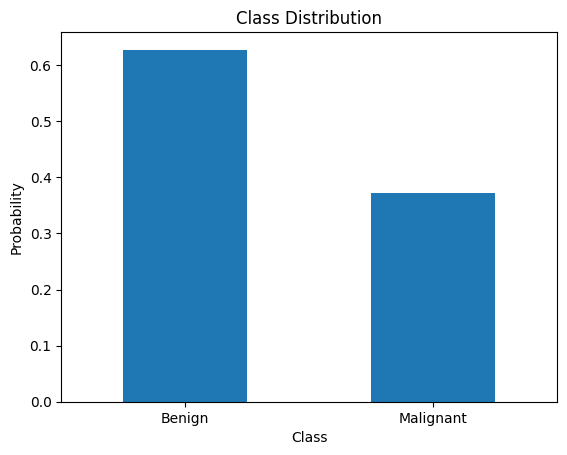

In [ ]:
class_distribution.plot(
    x="Class",
    y="Probability",
    kind="bar",
    legend=False,
    title="Class Distribution"
)

plt.ylabel("Probability")
plt.xlabel("Class")
plt.xticks(rotation=0)
plt.show()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training size:", len(y_train))
print("Testing size:", len(y_test))

print("\nTraining proportion:")
print(y_train.value_counts(normalize=True))

print("\nTesting proportion:")
print(y_test.value_counts(normalize=True))


Training size: 455
Testing size: 114

Training proportion:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Testing proportion:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


In [ ]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [ ]:
probabilities = model.predict_proba(X_test)

print(probabilities[:5])


[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [ ]:
print(probabilities[:5])


[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [ ]:
result = pd.DataFrame({
    "Actual_class": y_test.values,
    "p_malignant": probabilities[:, 1],
    "p_benign": probabilities[:, 0]
})

print(result.head())


   Actual_class  p_malignant      p_benign
0             0     0.000365  9.996354e-01
1             1     1.000000  1.074660e-08
2             0     0.042568  9.574321e-01
3             1     0.576187  4.238127e-01
4             0     0.509155  4.908445e-01


In [ ]:
threshold = 0.50

result["predicted_malignant"] = (
    result["p_malignant"] > threshold
).astype(int)

result["Predicted_label"] = result["predicted_malignant"].map({
    0: "benign",
    1: "malignant"
})

print(
    result[
        ["Actual_class", "Predicted_label", "p_malignant", "p_benign"]
    ].head(10)
)


   Actual_class Predicted_label  p_malignant      p_benign
0             0          benign     0.000365  9.996354e-01
1             1       malignant     1.000000  1.074660e-08
2             0          benign     0.042568  9.574321e-01
3             1       malignant     0.576187  4.238127e-01
4             0       malignant     0.509155  4.908445e-01
5             0          benign     0.000616  9.993840e-01
6             1       malignant     0.761534  2.384659e-01
7             0          benign     0.001012  9.989878e-01
8             0          benign     0.000569  9.994313e-01
9             0          benign     0.010768  9.892324e-01


In [ ]:
# Compare different thresholds
for threshold in [0.30, 0.50, 0.70]:
    predictions = (
        result["p_malignant"] >= threshold
    ).astype(int)

    print(
        f"Threshold = {threshold}: "
        f"Predicted malignant cases = {predictions.sum()}"
    )


Threshold = 0.3: Predicted malignant cases = 42
Threshold = 0.5: Predicted malignant cases = 40
Threshold = 0.7: Predicted malignant cases = 38


In [ ]:
from sklearn.metrics import confusion_matrix

threshold = 0.50

predictions = (
    result["p_malignant"] >= threshold
).astype(int)

cm = confusion_matrix(y_test, predictions)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[71  1]
 [ 3 39]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold = 0.50

y_pred = (
    result["p_malignant"] >= threshold
).astype(int)

print("Sklearn accuracy :", accuracy_score(y_test, y_pred))
print("Sklearn precision:", precision_score(y_test, y_pred))
print("Sklearn recall   :", recall_score(y_test, y_pred))
print("Sklearn F1       :", f1_score(y_test, y_pred))



Sklearn accuracy : 0.9649122807017544
Sklearn precision: 0.975
Sklearn recall   : 0.9285714285714286
Sklearn F1       : 0.9512195121951219


In [ ]:
matrix_result = []

for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:

    y_pred_threshold = (
        probabilities[:, 1] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    sensitivity = recall

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    matrix_result.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Sensitivity_recall": sensitivity,
        "Specificity": specificity,
        "F1": f1
    })

matrix_result = pd.DataFrame(matrix_result)

display(matrix_result.round(3))


,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,Sensitivity_recall,Specificity,F1
0,0.1,67,5,1,41,0.947,0.891,0.976,0.976,0.931,0.932
1,0.3,71,1,1,41,0.982,0.976,0.976,0.976,0.986,0.976
2,0.5,71,1,3,39,0.965,0.975,0.929,0.929,0.986,0.951
3,0.7,72,0,4,38,0.965,1.000,0.905,0.905,1.000,0.950
4,0.9,72,0,9,33,0.921,1.000,0.786,0.786,1.000,0.880


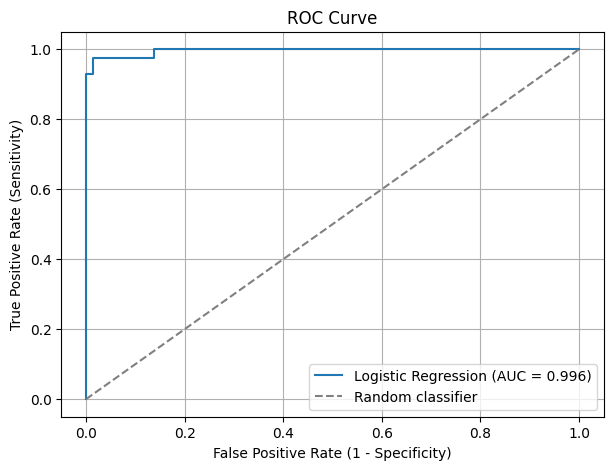

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Actual malignant probability
y_prob_malignant = probabilities[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_malignant
)

# Calculate AUC
auc_score = roc_auc_score(
    y_test,
    y_prob_malignant
)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()
